<a href="https://colab.research.google.com/github/Rizki-Code156/pm-turi4-clustering/blob/main/PM_TuRi4_Clustering_RizkiAidilFazri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#C. Langkah Praktikum

##Langkah 1 — Menyiapkan data & scaling (wajib).

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

data = {
    'usia': [19, 21, 20, 23, 31, 35, 40, 42, 25, 28],
    'pendapatan': [3, 4, 3.5, 5, 8, 9, 10, 12, 5.5, 6],
    'skor_belanja': [80, 75, 85, 70, 40, 35, 20, 15, 65, 60]
}

df = pd.DataFrame(data)

print("Dataset Pelanggan:")
print(df)

X_scaled = StandardScaler().fit_transform(df)

print("\nData Setelah Scaling:")
print(X_scaled)

Dataset Pelanggan:
   usia  pendapatan  skor_belanja
0    19         3.0            80
1    21         4.0            75
2    20         3.5            85
3    23         5.0            70
4    31         8.0            40
5    35         9.0            35
6    40        10.0            20
7    42        12.0            15
8    25         5.5            65
9    28         6.0            60

Data Setelah Scaling:
[[-1.18958754 -1.2579418   1.06597564]
 [-0.93648381 -0.90851353  0.85696081]
 [-1.06303567 -1.08322766  1.27499047]
 [-0.68338008 -0.55908525  0.64794598]
 [ 0.32903485  0.48919959 -0.60614301]
 [ 0.83524231  0.83862787 -0.81515784]
 [ 1.46800164  1.18805615 -1.44220234]
 [ 1.72110538  1.88691271 -1.65121717]
 [-0.43027634 -0.38437111  0.43893115]
 [-0.05062075 -0.20965697  0.22991631]]


##Langkah 2 — Metode Elbow menentukan K.

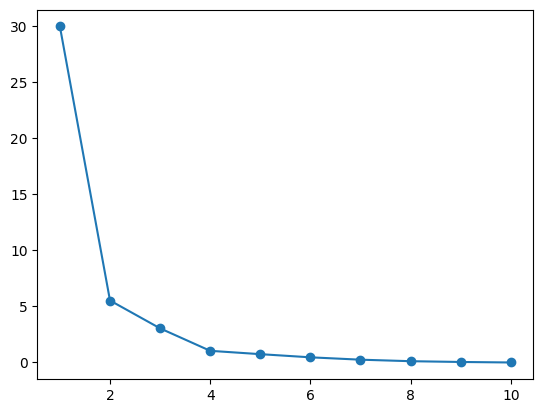

In [18]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


##Langkah 3 — Menjalankan K-Means (K=3).

In [19]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
0    6
2    2
1    2
Name: count, dtype: int64


##Langkah 4 — Evaluasi silhouette score.

In [20]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.56577470681843


##Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [21]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

nama_cluster = {}

# Penamaan cluster berdasarkan profil
for cluster, row in profil.iterrows():
    print(f"\nCluster {cluster}:")
    print(f"Usia rata-rata: {row['usia']}")
    print(f"Pendapatan rata-rata: {row['pendapatan']}")
    print(f"Skor belanja rata-rata: {row['skor_belanja']}")

# Beri nama berdasarkan karakteristik profil
    if row['skor_belanja'] >= 60:
        nama = 'Pelanggan Muda & Impulsif'
    elif row['pendapatan'] >= 8:
        nama = 'Pelanggan Senior & Hemat'
    else:
        nama = 'Pelanggan Mapan & Moderat'

    nama_cluster[cluster] = nama
    print(f"  --> Nama Cluster: {nama}")

df['nama_cluster'] = df['cluster'].map(nama_cluster)

         usia  pendapatan  skor_belanja
cluster                                
0        22.7         4.5          72.5
1        41.0        11.0          17.5
2        33.0         8.5          37.5

Cluster 0:
Usia rata-rata: 22.7
Pendapatan rata-rata: 4.5
Skor belanja rata-rata: 72.5
  --> Nama Cluster: Pelanggan Muda & Impulsif

Cluster 1:
Usia rata-rata: 41.0
Pendapatan rata-rata: 11.0
Skor belanja rata-rata: 17.5
  --> Nama Cluster: Pelanggan Senior & Hemat

Cluster 2:
Usia rata-rata: 33.0
Pendapatan rata-rata: 8.5
Skor belanja rata-rata: 37.5
  --> Nama Cluster: Pelanggan Senior & Hemat


#D. Latihan Mandiri

##6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [22]:
# K-Means dengan K=5
kmeans5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster5 = kmeans5.fit_predict(X_scaled)

# Menghitung silhouette score K=5
score5 = silhouette_score(X_scaled, cluster5)

# Menghitung silhouette score K=3
score3 = silhouette_score(X_scaled, df['cluster'])

print("Silhouette Score K=3:", score3)
print("Silhouette Score K=5:", score5)

if score5 > score3:
    print("K=5 memiliki hasil clustering yang lebih baik.")
elif score5 < score3:
    print("K=3 memiliki hasil clustering yang lebih baik.")
else:
    print("K=3 dan K=5 memiliki silhouette score yang sama.")

Silhouette Score K=3: 0.56577470681843
Silhouette Score K=5: 0.41707483588408456
K=3 memiliki hasil clustering yang lebih baik.


##7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [23]:
# K-Means tanpa scaling dengan K=3
kmeans_no_scaling = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_no_scaling = kmeans_no_scaling.fit_predict(
    df[['usia', 'pendapatan', 'skor_belanja']]
)

# Menghitung silhouette score tanpa scaling
score_no_scaling = silhouette_score(
    df[['usia', 'pendapatan', 'skor_belanja']],
    cluster_no_scaling
)

# Membandingkan silhouette score
print("Silhouette Score dengan Scaling:", score3)
print("Silhouette Score tanpa Scaling:", score_no_scaling)

if score3 > score_no_scaling:
    print("Scaling menghasilkan silhouette score yang lebih tinggi.")
elif score3 < score_no_scaling:
    print("Tanpa scaling menghasilkan silhouette score yang lebih tinggi.")
else:
    print("Keduanya menghasilkan silhouette score yang sama.")

Silhouette Score dengan Scaling: 0.56577470681843
Silhouette Score tanpa Scaling: 0.6625938960375198
Tanpa scaling menghasilkan silhouette score yang lebih tinggi.


##8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

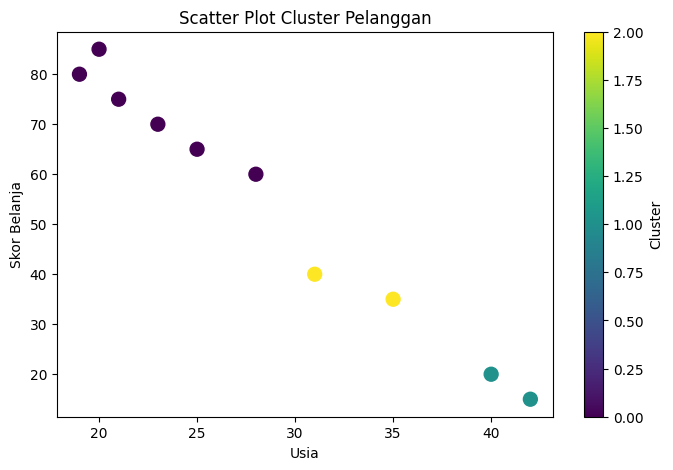

In [24]:
# Scatter plot hasil clustering
plt.figure(figsize=(8, 5))

plt.scatter(
    df['usia'],
    df['skor_belanja'],
    c=df['cluster'],
    cmap='viridis',
    s=100
)

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster Pelanggan')
plt.colorbar(label='Cluster')
plt.show()

#E. Refleksi

##9. Bagaimana K-Means menemukan kelompok tanpa label?


K-Means mengelompokkan data berdasarkan kemiripan dan jarak antar data.

##10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Karena pada K=3, penurunan inertia mulai melambat sehingga 3 cluster dianggap cukup optimal.

##11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Scaling membuat skala data menjadi seimbang. Jika tidak dilakukan, data dengan nilai lebih besar bisa lebih memengaruhi hasil pengelompokan.